---
title: "Lecture 15: Concentration Inequalities, Weak Law of Large Numbers"
author: "Jamie Haddock"
format:
    revealjs:
        output-file: Lecture15_slides
        slide-number: true
        preview-links: auto
        logo: figs/hmc.png
        css: input/slides.css
        incremental: true
        smaller: true
        code-fold: true
        embed-resources: true
        html-math-method: katex
        slide-level: 3
    html:
        code-fold: true
        embed-resources: true
        output-file: Lecture15
        code-links:
          - text: "Open in Colab"
            href: "https://colab.research.google.com/github/jamiehadd/Math-151-Probability/blob/main/15_concentration-inequalities-wlln.ipynb"
            icon: "laptop"
    pdf:
        documentclass: article
        toc: true
        number-sections: true
        output-file: Lecture15
        geometry:
          - top=1in
          - left=1in
          - bottom=1in
          - right=1in
format-links: false
jupyter: python3
colab:
  gh-user: "jamiehadd"
  gh-repo: "Math-151-Probability"
filters:
  - input/remove-pause.lua
  - colab
execute:
  echo: true
  eval: true
---

# Motivation

This week, we'll be investigating probability topics related to the asymptotic behavior of sequences of random variables.

In particular, we're interested in what happens to sums and averages of random variables as the number of random variable summands $n \to \infty$?

## Motivating calculations

Let $X_1, \dots, X_n$ be i.i.d. with mean $\mu$ and variance $\sigma^2$. Define
$$S_n = X_1 + \cdots + X_n, \qquad \bar{X}_n = \frac{S_n}{n}.$$

- $E[S_n] = n\mu$ and $\operatorname{Var}(S_n) = n\sigma^2$: mean and variance gets big as $n \to \infty$, the distribution spreads out!
- $E[\bar{X}_n] = \mu$ and $\operatorname{Var}(\bar{X}_n) = \dfrac{\sigma^2}{n} \to 0$ as $n \to \infty$.  The distribution centers around $\mu$ tighter and tighter!

. . .

This is the mathematical basis for thinking of $E[X]$ as the average of a large number of independent samples.

## "Standardizing" $S_n$

$S_n$ and $\bar{X}_n$ are at opposite ends of a spectrum (spreading out and shrinking) -- what if we consider a different sequence where mean and variance stay constant?

. . .

$$Z_n = \frac{S_n - n\mu}{\sigma\sqrt{n}}$$

- $E[Z_n] = 0$ and $\operatorname{Var}(Z_n) = 1$.
- $S_n - n\mu$ centers the sum around zero; dividing by $\sigma\sqrt{n}$ fixes the variance to 1.

. . .

Preview: what does the distribution of $Z_n$ look like? Lots of distributions have mean 0 and variance 1, but they differ in their shape (revealed by PMF/PDF or CDF)! This will be the **central limit theorem (CLT)** which we'll talk about next lecture.

### Example: $Z_n$ where $X_i \sim \text{Bernoulli}(p)$

Suppose $X_1, \cdots, X_n$ are i.i.d. $\text{Bernoulli}(p)$ and let $S_n = X_1 + \cdots + X_n$.  

. . .

Let's look at some plots of realizations of samples of $Z_n = \frac{S_n - n\mu}{\sigma\sqrt{n}}$ as $n \rightarrow \infty$.  

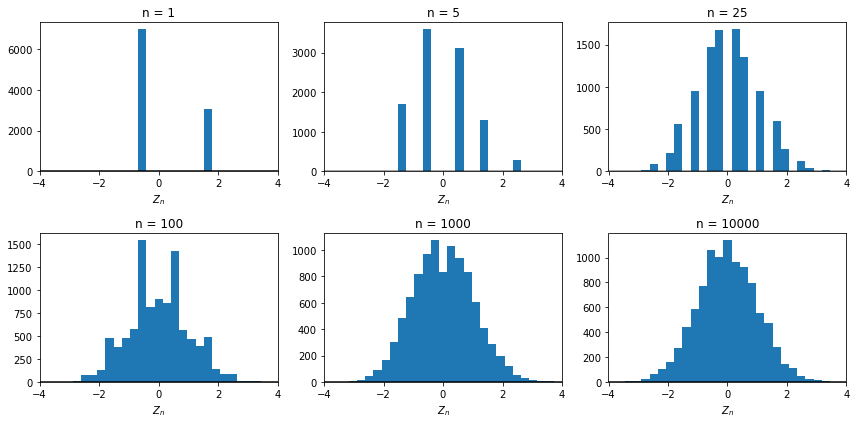

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(151)

p = 0.3
sigma = np.sqrt(p * (1 - p))
reps = 10_000                       # simulated copies of Z_n for each n
ns = [1, 5, 25, 100, 1000, 10_000]

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
x = np.linspace(-4, 4, 400)

for ax, n in zip(axes.flat, ns):
    # S_n ~ Binomial(n, p)
    S = rng.binomial(n, p, size=reps)
    z = (S - n * p) / (sigma * np.sqrt(n))       # Z_n = (S_n - np) / (sigma sqrt(n))

    ax.hist(z, bins=np.linspace(-4, 4, 30), density=False)
    ax.plot(x, norm.pdf(x), "k")
    ax.set_xlim(-4, 4)
    ax.set_title(f"n = {n}")
    ax.set_xlabel(r"$Z_n$")

plt.tight_layout()
plt.show()

# Concentration Inequalities or Tail Bounds

::: {.callout-note title="Definition"}
A **concentration inequality** (or **tail bound**) is an upper bound on the probability that a random variable occurs far from its mean.
:::

## Markov's Inequality

The most fundamental tail bound is Markov's inequality.

::: {.callout-note title="Theorem (Markov)"}
If $X$ can take only nonnegative values and $a > 0$, then
$$P(X \ge a) \le \frac{E[X]}{a}.$$
:::

. . .

**Proof.** Define $Y_a$ to be an indicator random variable, $$Y_a = \begin{cases} 0 & \text{ if } X < a \\ 1 & \text{ if } X \ge a \end{cases}.$$ 

. . .

Since $X \ge 0$, we have $a \cdot Y_a \le X$ pointwise. (Check the two cases!) 

. . .

Taking expectations gives $a\,P(X \ge a) = a\,E[Y_a] \le E[X]$. $\square$

### Visualization: Markov's Inequality

:::: {.columns}

::: {.column width="55%"}
![](figs/Markov.jpeg){height=600}
:::

::: {.column width="45%"}
Since probability mass is shifted to the left, the expectation can only decrease!
:::

::::


### Exercise

::: {.callout-tip title="Exercise"}
Let $X \sim \text{Exp}(1)$ be an exponential random variable. Use Markov's inequality to bound $P(X \ge a)$ and compare with the exact value.
:::

<details>
<summary>Solution</summary>

Since $X \sim \text{Exp}(1)$, $X \ge 0$ and $E[X] = 1$. Markov's inequality gives, for $a > 0$,
$$P(X \ge a) \le \frac{E[X]}{a} = \frac{1}{a}.$$

The exact value is
$$P(X \ge a) = \int_a^\infty e^{-x}\,dx = e^{-a}.$$

</details>

---

| $a$ | Markov bound $1/a$ | Exact $e^{-a}$ |
|---|---|---|
| 1 | 1 | 0.368 |
| 2 | 0.5 | 0.135 |
| 5 | 0.2 | 0.0067 |
| 10 | 0.1 | 0.0000454 |

Markov is valid but loose: it decays like $1/a$, while the true tail decays exponentially. (For $a \le 1$ the bound is trivial.)


## Chebyshev's Inequality

Now, we turn to a slightly stronger concentration inequality.  Note that this applies to random variables with finite mean and variance!

::: {.callout-note title="Theorem (Chebyshev)"}
If $X$ is a random variable with mean $\mu$ and variance $\sigma^2$, then for $c > 0$
$$P(|X - \mu| \ge c) \le \frac{\sigma^2}{c^2}.$$
:::

. . .

**Proof.** Let $Y = (X - \mu)^2$. Then $Y \ge 0$, so Markov's inequality applies to $Y$.

. . .

For $c > 0$, these events are the same:
$$|X - \mu| \ge c \iff (X - \mu)^2 \ge c^2.$$

. . .

Apply Markov to $Y$ with $a = c^2$:
$$P(|X - \mu| \ge c) = P(Y \ge c^2) \le \frac{E[Y]}{c^2} = \frac{E[(X-\mu)^2]}{c^2} = \frac{\sigma^2}{c^2}. \qquad \square$$

---


::: {.callout-warning title="Alternative form"}
Take $c = k\sigma$:
$$P(|X - \mu| \ge k\sigma) \le \frac{\sigma^2}{k^2 \sigma^2} = \frac{1}{k^2}.$$
:::


### Exercise

::: {.callout-tip title="Exercise"}
Let $X \sim \text{Exp}(1)$. Use Chebyshev's inequality to bound $P(|X - 1| \ge c)$ and compare with the exact value.
:::

<details>
<summary>Solution</summary>

For $X \sim \text{Exp}(1)$, $\mu = E[X] = 1$ and $\sigma^2 = \operatorname{Var}(X) = 1$. Chebyshev's inequality gives, for $c > 0$,
$$P(|X - 1| \ge c) \le \frac{\sigma^2}{c^2} = \frac{1}{c^2}.$$

**Exact value.** The event $|X - 1| \ge c$ means $X \ge 1 + c$ or $X \le 1 - c$. For $c > 1$, the second is impossible since $X \ge 0$, so
$$P(|X - 1| \ge c) = P(X \ge 1 + c) = e^{-(1+c)}.$$
(For $0 < c \le 1$ there is an extra term: $e^{-(1+c)} + 1 - e^{-(1-c)}$.)

</details>

---

| $c$ | Chebyshev bound $1/c^2$ | Exact |
|---|---|---|
| 1 | 1 | 0.135 |
| 2 | 0.25 | 0.0498 |
| 3 | 0.111 | 0.0183 |
| 5 | 0.04 | 0.00248 |

Chebyshev is valid but loose: it decays like $1/c^2$, while the true tail decays exponentially. (For $c \le 1$ the bound is trivial.)

# Weak Law of Large Numbers (WLLN)

Now we turn to the Weak Law of Large Numbers, which answers the question: How often does the sample mean $\bar{X}_n$ stay near $\mu$?

## Application to $\bar{X}_n$ where $X_i \sim \text{Bernoulli}(p)$

**Markov:** $P(\bar{X}_n \ge a) \le p/a$, which does not shrink with $n$.

. . .

The variance of $\bar{X}_n$ is going to 0 as $n \rightarrow \infty$, so we should be able to do better than a constant tail bound probability!  The answer is to apply Chebyshev's inequality (if the random variables have finite variance). 

## Weak Law of Large Numbers

::: {.callout-note title="Theorem (WLLN)"}
Let $X_1, X_2, \dots$ be i.i.d. with mean $\mu$. For every $\varepsilon > 0$,
$$P(|\bar{X}_n - \mu| \ge \varepsilon) \to 0 \quad \text{as } n \to \infty.$$
:::

. . .

**Proof (for case where $\text{Var}(X_i) = \sigma^2$).** Assume $\sigma^2 < \infty$. Fix $\varepsilon > 0$.

By linearity of expectation and independence,
$$E[\bar{X}_n] = \mu, \qquad \operatorname{Var}(\bar{X}_n) = \frac{1}{n^2}\sum_{i=1}^n \operatorname{Var}(X_i) = \frac{\sigma^2}{n}.$$

. . .

Apply Chebyshev to $\bar{X}_n$ with $c = \varepsilon$:
$$P(|\bar{X}_n - \mu| \ge \varepsilon) \le \frac{\operatorname{Var}(\bar{X}_n)}{\varepsilon^2} = \frac{\sigma^2}{n\varepsilon^2}.$$

. . .

The right side goes to $0$ as $n \to \infty$ for fixed $\varepsilon > 0$, so
$P(|\bar{X}_n - \mu| \ge \varepsilon) \to 0.$

---

**Intuition.** For large $n$, $\bar{X}_n$ lies in the interval $(\mu - \varepsilon, \mu + \varepsilon)$ with probability close to 1, however small $\varepsilon$ is.  Smaller $\varepsilon$ just requires larger values of $n$!

### Example: polling

Suppose we want to estimate the fraction $p$ of voters supporting a candidate. How many people must we poll so the estimate is within $0.01$ of $p$ with probability at least $0.95$?

. . .

Interview $n$ "randomly selected" voters and let $X_i$ be an indicator random variable that indicates if voter $i$ supports the candidate.  Then $\bar{X}_n$ is the fraction of the $n$ voters supporting the candidate.

. . .

Note that the $X_i \sim \text{Bernoulli}(p)$ are independent, so Chebyshev yields $$P(|\bar{X}_n - p| \ge \epsilon) \le \frac{p(1-p)}{n\epsilon^2} \le \frac{1}{4n\epsilon^2}$$.  

---

Now, if we want the gap $\epsilon = 0.01$ and the probability $$P(|\bar{X}_n - p| \ge \epsilon) \le 1 - 0.95 = 0.05,$$ then we can achieve this by choosing $n$ such that the upper bound is less than $0.05$, $$\frac{1}{4n(0.01)^2} \le 0.05$$ or $n \ge 50000$.

### Example: Cauchy RV sample mean

A **standard Cauchy** random variable has PDF
$$f_X(x) = \frac{1}{\pi(1 + x^2)}, \qquad x \in \mathbb{R}.$$

It is symmetric and bell-shaped like the normal, but its tails are much heavier:
$$P(|X| \ge a) = \frac{2}{\pi}\arctan\!\left(\frac{1}{a}\right) \approx \frac{2}{\pi a} \quad \text{for large } a.$$
(It is also the ratio of two independent $N(0,1)$ random variables.)

. . .

If the $X_i$ are standard Cauchy, $\bar{X}_n$ is again standard Cauchy for every $n$: it never concentrates.

---

**Why doesn't the WLLN apply?** The expectation does not exist:
$$E|X| = 2\int_0^\infty \frac{x}{\pi(1+x^2)}\,dx = \frac{1}{\pi}\Big[\ln(1+x^2)\Big]_0^\infty = \infty.$$
The positive part of $X$ contributes $+\infty$ and the negative part $-\infty$, so $E[X]$ is undefined.

. . .

Markov's inequality applied to $|X|$ gives
$$P(|X| \ge a) \le \frac{E|X|}{a} = \infty,$$
which says nothing. Chebyshev needs a finite variance, so it fails too.

::: {.callout-warning title="Warning"}
The WLLN fails here because $E[X]$ does not exist: Markov (and hence Chebyshev) gives no information.
:::

# Convergence in Probability

**Reminder:** A deterministic (non-random) sequence $\{a_n\}_{n=1}^\infty$ is said to *converge* $a_n \to a$ if for every $\varepsilon > 0$ there is $n_0$ such that
$$|a_n - a| < \varepsilon \quad \text{for all } n \ge n_0.$$

## Convergence in Probability

We are interested in convergence of random variables now.

::: {.callout-note title="Definition"}
Let $Y_1, Y_2, \cdots$ be a sequence of random variables and let $a$ be a real number.  We say that the sequence **$Y_n$ converges to $a$ in probability** if for every $\varepsilon > 0$, we have
$$\lim_{n\rightarrow \infty} P(|Y_n - a| \ge \varepsilon) = 0.$$
:::

. . .

**WLLN interpretation:** $\bar{X}_n \to \mu$ in probability.

---

::: {.callout-note title="Alternative form"}
$Y_n$ converges to $a$ in probability if for every $\varepsilon > 0$ and every $\delta > 0$ there is an $n_0$ such that
$$P(|Y_n - a| \ge \varepsilon) \le \delta \quad \text{for all } n \ge n_0.$$
Here $\varepsilon$ is the accuracy and $1 - \delta$ is the confidence.
:::

. . .

::: {.callout-warning title="Warning"}
$n_0$ depends on both $\varepsilon$ and $\delta$: more accuracy or more confidence requires larger $n$.
:::

### Example: Min of Uniform RVs

Let $U_1, \dots, U_n$ be i.i.d. $\text{Uniform}(0,1)$ and $Y_n = \min(U_1, \dots, U_n)$. Where does $Y_n$ converge?

. . .

$Y_n \to 0$ in probability: for $0 < \varepsilon < 1$,
$$P(|Y_n - 0| \ge \varepsilon) = P(Y_n \ge \varepsilon) = (1 - \varepsilon)^n \to 0.$$

. . . 

::: {.callout-tip title="Exercise"}
Given accuracy $\varepsilon$ and confidence $1 - \delta$, find $n_0$ such that $P(|Y_n| \ge \varepsilon) \le \delta$ for all $n \ge n_0$.
:::

<details>
<summary>Solution</summary>

For $0 < \varepsilon < 1$ we showed $P(|Y_n| \ge \varepsilon) = (1 - \varepsilon)^n$. We need
$$(1 - \varepsilon)^n \le \delta \iff n \ln(1 - \varepsilon) \le \ln \delta \iff n \ge \frac{\ln \delta}{\ln(1 - \varepsilon)},$$
where the inequality flips because $\ln(1 - \varepsilon) < 0$. So take
$n_0 = \left\lceil \frac{\ln \delta}{\ln(1 - \varepsilon)} \right\rceil.$
Since $(1 - \varepsilon)^n$ is decreasing in $n$, the bound then holds for all $n \ge n_0$.

</details>